In [ ]:
# Task 27: Distribution Analysis

## Objective
Create a histogram for a numerical variable and analyze
the distribution of its values.

## Deliverables
- Student marks dataset
- Histogram of student marks
- Statistical summary
- Description of the distribution
- At least three observations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Create student marks dataset

marks = [
    35, 42, 48, 52, 55,
    58, 60, 61, 62, 63,
    64, 65, 66, 67, 68,
    68, 69, 70, 71, 72,
    73, 74, 75, 76, 78,
    80, 82, 85, 90, 96
]

# Create student IDs
student_ids = [
    f"S{i:03d}" for i in range(1, 31)
]

# Create DataFrame
df = pd.DataFrame({
    "student_id": student_ids,
    "marks": marks
})

print("Student marks dataset created successfully!")

print("Total students:", len(df))

display(df.head(10))

Student marks dataset created successfully!
Total students: 30


,student_id,marks
0,S001,35
1,S002,42
2,S003,48
3,S004,52
4,S005,55
5,S006,58
6,S007,60
7,S008,61
8,S009,62
9,S010,63


In [3]:
# Export dataset
df.to_csv("student_marks.csv", index=False)

# Load dataset
df = pd.read_csv("student_marks.csv")

print("Dataset loaded successfully!")

display(df)

Dataset loaded successfully!


,student_id,marks
0,S001,35
1,S002,42
2,S003,48
3,S004,52
4,S005,55
5,S006,58
6,S007,60
7,S008,61
8,S009,62
9,S010,63


In [4]:
print("DATASET INFORMATION")

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

DATASET INFORMATION
Total rows: 30
Total columns: 2

Column names:
['student_id', 'marks']

Data types:
student_id    object
marks          int64
dtype: object

First five records:


,student_id,marks
0,S001,35
1,S002,42
2,S003,48
3,S004,52
4,S005,55



Last five records:


,student_id,marks
25,S026,80
26,S027,82
27,S028,85
28,S029,90
29,S030,96


In [5]:
print("STATISTICAL SUMMARY OF STUDENT MARKS")

display(df["marks"].describe())

STATISTICAL SUMMARY OF STUDENT MARKS


,marks
count,30.000000
mean,67.500000
std,13.245038
min,35.000000
25%,61.250000
50%,68.000000
75%,74.750000
max,96.000000


In [6]:
marks_data = df["marks"]

mean_marks = marks_data.mean()
median_marks = marks_data.median()
std_marks = marks_data.std()

minimum_marks = marks_data.min()
maximum_marks = marks_data.max()

range_marks = maximum_marks - minimum_marks

skewness = marks_data.skew()

print("=" * 50)
print("       STUDENT MARKS DISTRIBUTION ANALYSIS")
print("=" * 50)

print(f"Total students: {len(marks_data)}")
print(f"Mean: {mean_marks:.2f}")
print(f"Median: {median_marks:.2f}")
print(f"Standard deviation: {std_marks:.2f}")
print(f"Minimum marks: {minimum_marks}")
print(f"Maximum marks: {maximum_marks}")
print(f"Range: {range_marks}")
print(f"Skewness: {skewness:.3f}")

       STUDENT MARKS DISTRIBUTION ANALYSIS
Total students: 30
Mean: 67.50
Median: 68.00
Standard deviation: 13.25
Minimum marks: 35
Maximum marks: 96
Range: 61
Skewness: -0.289


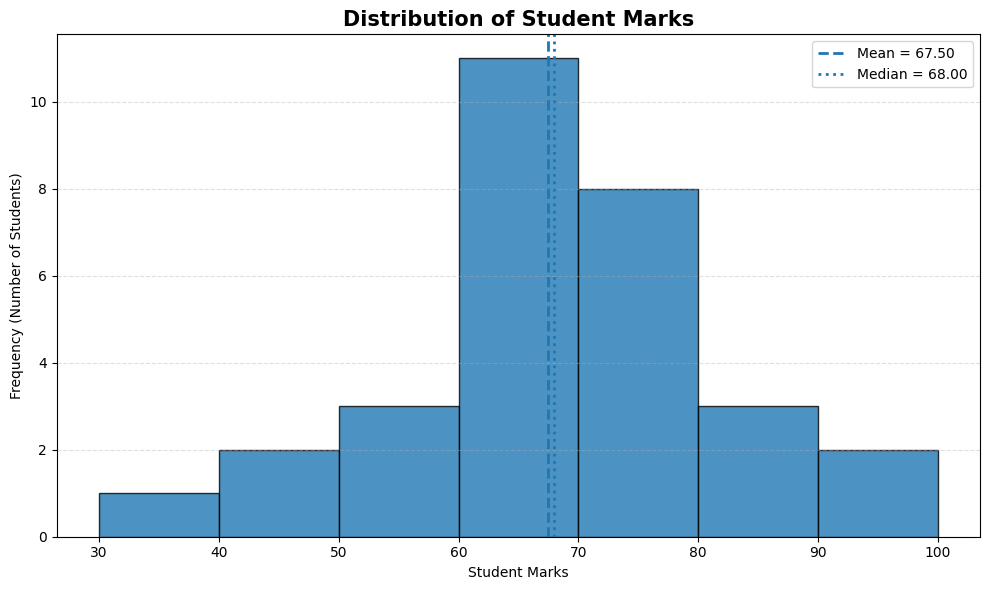

In [7]:
# Create charts folder
Path("charts").mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

# Define histogram bins
bins = np.arange(30, 101, 10)

plt.hist(
    marks_data,
    bins=bins,
    edgecolor="black",
    alpha=0.8
)

# Display mean and median
plt.axvline(
    mean_marks,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_marks:.2f}"
)

plt.axvline(
    median_marks,
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_marks:.2f}"
)

plt.title(
    "Distribution of Student Marks",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Student Marks")
plt.ylabel("Frequency (Number of Students)")

plt.xticks(bins)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "charts/marks_distribution_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

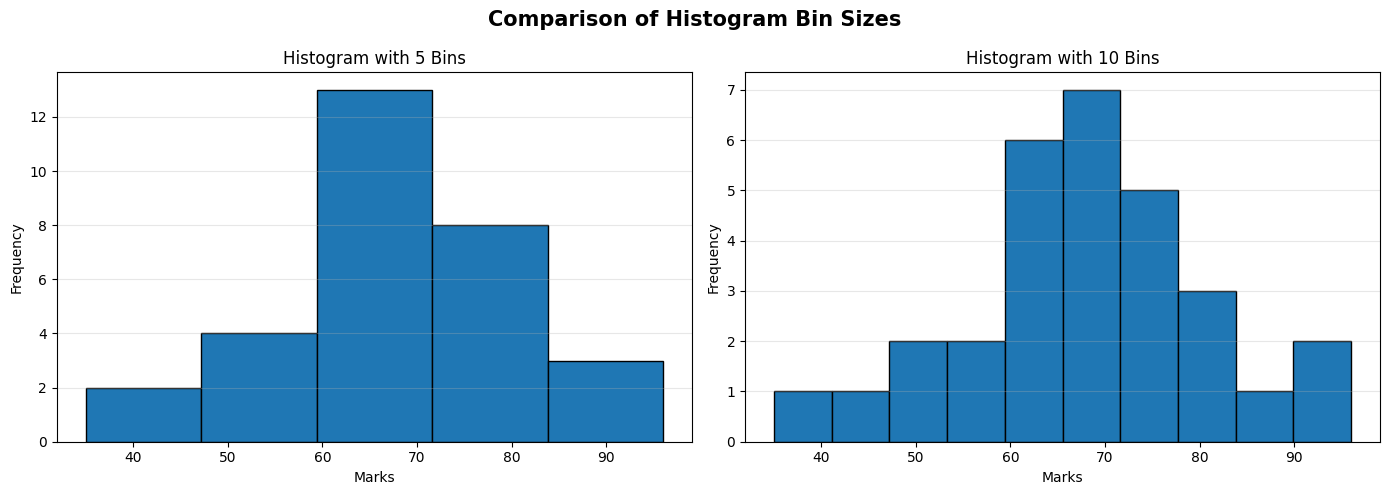

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with 5 bins
axes[0].hist(
    marks_data,
    bins=5,
    edgecolor="black"
)

axes[0].set_title("Histogram with 5 Bins")
axes[0].set_xlabel("Marks")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", alpha=0.3)

# Histogram with 10 bins
axes[1].hist(
    marks_data,
    bins=10,
    edgecolor="black"
)

axes[1].set_title("Histogram with 10 Bins")
axes[1].set_xlabel("Marks")
axes[1].set_ylabel("Frequency")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Comparison of Histogram Bin Sizes",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [9]:
bins = [30, 40, 50, 60, 70, 80, 90, 100]

labels = [
    "30–39",
    "40–49",
    "50–59",
    "60–69",
    "70–79",
    "80–89",
    "90–99"
]

df["marks_range"] = pd.cut(
    df["marks"],
    bins=bins,
    labels=labels,
    right=False
)

frequency_table = (
    df["marks_range"]
    .value_counts(sort=False)
    .reset_index()
)

frequency_table.columns = [
    "Marks Interval",
    "Number of Students"
]

print("STUDENT MARKS FREQUENCY DISTRIBUTION")

display(frequency_table)

STUDENT MARKS FREQUENCY DISTRIBUTION


,Marks Interval,Number of Students
0,30–39,1
1,40–49,2
2,50–59,3
3,60–69,11
4,70–79,8
5,80–89,3
6,90–99,2


In [10]:
# Calculate distribution observations

q1 = marks_data.quantile(0.25)
q3 = marks_data.quantile(0.75)

students_60_79 = marks_data[
    (marks_data >= 60) &
    (marks_data < 80)
].count()

percentage_60_79 = (
    students_60_79 / len(marks_data)
) * 100

print("=" * 55)
print("          DISTRIBUTION ANALYSIS OBSERVATIONS")
print("=" * 55)

print(
    f"\n1. {students_60_79} out of {len(marks_data)} students "
    f"({percentage_60_79:.2f}%) scored between 60 and 79."
)

print(
    f"\n2. Mean marks are {mean_marks:.2f}, "
    f"while median marks are {median_marks:.2f}."
)

print(
    f"\n3. The standard deviation is {std_marks:.2f}, "
    f"indicating the spread of marks around the mean."
)

print(
    f"\n4. The skewness is {skewness:.3f}."
)

if skewness < 0:
    print("The distribution is slightly negatively skewed.")
elif skewness > 0:
    print("The distribution is positively skewed.")
else:
    print("The distribution has approximately zero skewness.")

print(
    f"\n5. Marks range from {minimum_marks} "
    f"to {maximum_marks}, giving a range of {range_marks}."
)

print(f"\nFirst quartile (Q1): {q1:.2f}")
print(f"Third quartile (Q3): {q3:.2f}")

          DISTRIBUTION ANALYSIS OBSERVATIONS

1. 19 out of 30 students (63.33%) scored between 60 and 79.

2. Mean marks are 67.50, while median marks are 68.00.

3. The standard deviation is 13.25, indicating the spread of marks around the mean.

4. The skewness is -0.289.
The distribution is slightly negatively skewed.

5. Marks range from 35 to 96, giving a range of 61.

First quartile (Q1): 61.25
Third quartile (Q3): 74.75


In [11]:
distribution_summary = pd.DataFrame({
    "Metric": [
        "Total Students",
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "Maximum",
        "Range",
        "Skewness",
        "First Quartile",
        "Third Quartile",
        "Students Scoring 60-79",
        "Percentage Scoring 60-79"
    ],

    "Value": [
        len(marks_data),
        round(mean_marks, 2),
        round(median_marks, 2),
        round(std_marks, 2),
        minimum_marks,
        maximum_marks,
        range_marks,
        round(skewness, 3),
        round(q1, 2),
        round(q3, 2),
        students_60_79,
        round(percentage_60_79, 2)
    ]
})

display(distribution_summary)

,Metric,Value
0,Total Students,30.000
1,Mean,67.500
2,Median,68.000
3,Standard Deviation,13.250
4,Minimum,35.000
5,Maximum,96.000
6,Range,61.000
7,Skewness,-0.289
8,First Quartile,61.250
9,Third Quartile,74.750


In [12]:
df.to_csv(
    "student_marks.csv",
    index=False
)

distribution_summary.to_csv(
    "distribution_summary.csv",
    index=False
)

frequency_table.to_csv(
    "marks_frequency_table.csv",
    index=False
)

print("All project CSV files exported successfully!")

All project CSV files exported successfully!


In [13]:
from google.colab import files

files.download("student_marks.csv")
files.download("distribution_summary.csv")
files.download("marks_frequency_table.csv")
files.download("charts/marks_distribution_histogram.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>